# Fine-tune Qwen2.5-7B-Instruct (LoRA) trên Kaggle TPU

**Settings:** Accelerator = *TPU VM* (v5e-8 hoặc v3-8), Internet = *On*, Add Data = dataset chứa thư mục `traindata`.

Chạy lần lượt từng cell (hoặc *Run All*). Kết quả nằm ở `/kaggle/working/output` (adapter tốt nhất, biểu đồ, `report.md`, `metrics.json`).

Nếu phiên Kaggle hết giờ giữa chừng: *Save Version* với output, chạy lại notebook — `RESUME=True` sẽ train tiếp từ checkpoint (cần đưa `/kaggle/working/output` của phiên trước vào lại, hoặc dùng *Persistence* của Kaggle).

---

Fine-tune Qwen2.5-7B-Instruct (LoRA) trên Kaggle TPU (PyTorch/XLA SPMD) theo idea.docx.


Khác với idea.docx (bắt buộc vì phần cứng):
- TPU không chạy được bitsandbytes 4-bit nên dùng LoRA trên trọng số bf16 (cùng r/alpha/dropout/target),
trọng số chia (shard) trên 8 lõi TPU bằng SPMD (tương đương FSDP).
Giữ đúng idea.docx: loss chỉ trên lượt assistant cuối (+ <|im_end|>), max 4096 token, cắt lịch sử cũ nhất khi quá dài,
LR 2e-4 cosine warmup 3%, batch hiệu dụng 16, 3 epoch + early stopping (patience 3) theo val loss, seed 42,
validation 10% mỗi nhóm, val loss riêng từng nhóm, test không dùng khi train.

## 0. Cài đặt thư viện

In [1]:
%pip install -q transformers==4.46.3 peft==0.13.2 accelerate==1.1.1 rouge-score==0.1.2 bert-score==0.3.13 nltk matplotlib
# Sau khi cài xong, nếu Kaggle báo cần restart kernel thì Restart rồi chạy tiếp từ cell dưới.


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Cấu hình

In [2]:
import os, glob, json, math, random, time, re, copy, functools
from collections import defaultdict, Counter

CFG = dict(
    MODEL_ID="Qwen/Qwen2.5-7B-Instruct",
    DATA_DIR=None,                     # None = tự tìm thư mục chứa group_A_formatted.jsonl trong /kaggle/input
    OUT_DIR="/kaggle/working/output",
    SEED=42,
    MAX_LEN=4096,
    # LoRA (idea.docx)
    LORA_R=16, LORA_ALPHA=32, LORA_DROPOUT=0.05,
    LORA_TARGETS=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    # Huấn luyện
    NUM_EPOCHS=3,
    LR=2e-4, WARMUP_RATIO=0.03, WEIGHT_DECAY=0.0, MAX_GRAD_NORM=1.0,
    PER_DEVICE_BS=1,                   # batch mỗi lõi TPU; batch toàn cục = số lõi x PER_DEVICE_BS
    GRAD_ACCUM=2,                      # 8 lõi x 1 x 2 = batch hiệu dụng 16 (idea.docx: 16-32)
    VAL_RATIO=0.10,
    EVALS_PER_EPOCH=4,                 # đánh giá val 4 lần mỗi epoch
    EARLY_STOP_PATIENCE=3,             # dừng nếu val loss không giảm 3 lần đánh giá liên tiếp
    LOG_EVERY=10,                      # ghi train loss mỗi 10 bước optimizer
    # idea.docx đề xuất nhân B x3 khi B ~864 mẫu; hiện B (~3.770) đã ngang A (~3.450) nên để 1.
    OVERSAMPLE={"A": 1, "B1": 1, "B2": 1, "B3": 1, "B4": 1},
    NUM_BUCKETS=3,                     # số độ dài padding cố định (mỗi độ dài = 1 lần biên dịch XLA)
    TIME_LIMIT_HOURS=7.0,              # Kaggle giới hạn 9h/phiên: dừng train an toàn, chừa ~2h cho đánh giá
    RESUME=True,                       # nếu có checkpoint trong OUT_DIR thì train tiếp
    PREV_OUTPUT_DIR="auto",            # "auto" = tự tìm checkpoint.pt trong /kaggle/input (output phiên trước được Add Input); None = tắt
    # Đánh giá
    EVAL_BASE_MODEL=True,              # so sánh với model gốc (perplexity + sinh văn bản)
    N_GEN_PER_GROUP=40,                # số mẫu test mỗi nhóm để sinh và chấm ROUGE/BERTScore (None = toàn bộ, rất lâu)
    GEN_MAX_NEW_TOKENS=1024,
    BERTSCORE_MODEL="xlm-roberta-large",  # đa ngôn ngữ, có tiếng Việt; chạy trên CPU
)

GROUP_FILES = {
    "A":  ("group_A_formatted.jsonl", "test_A_formatted.jsonl"),
    "B1": ("group_B_B1.jsonl", "test_B_B1.jsonl"),
    "B2": ("group_B_B2.jsonl", "test_B_B2.jsonl"),
    "B3": ("group_B_B3.jsonl", "test_B_B3.jsonl"),
    "B4": ("group_B_B4.jsonl", "test_B_B4.jsonl"),
}
GROUPS = list(GROUP_FILES)

FIXED_PROMPT = ("Bạn là chuyên gia tư vấn tâm lý. Luôn phản hồi bằng sự thấu cảm.\nCHỈ gợi ý thực phẩm khi ROUTE_NUTRITION = true, "
                "và CHỈ dùng thực phẩm có trong [NUTRITION_CONTEXT], kèm mã nguồn. Nếu có MISSING_STATES, khéo léo hỏi thêm 1–2 thông tin còn thiếu. Trả về đúng JSON.")
OUTPUT_KEYS = {"thought_process", "side_talk", "nutritional_advice", "source_reference"}

os.makedirs(CFG["OUT_DIR"], exist_ok=True)
REPORT_DIR = os.path.join(CFG["OUT_DIR"], "report"); os.makedirs(REPORT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(CFG["OUT_DIR"], "checkpoint.pt")
BEST_DIR = os.path.join(CFG["OUT_DIR"], "best_adapter")
LOG_FILE = os.path.join(CFG["OUT_DIR"], "run_log.txt")
if CFG["PREV_OUTPUT_DIR"] == "auto":
    _hits = glob.glob("/kaggle/input/**/checkpoint.pt", recursive=True)
    CFG["PREV_OUTPUT_DIR"] = os.path.dirname(_hits[0]) if _hits else None
if CFG["PREV_OUTPUT_DIR"] and not os.path.exists(CKPT_PATH):
    import shutil
    shutil.copytree(CFG["PREV_OUTPUT_DIR"], CFG["OUT_DIR"], dirs_exist_ok=True)
    print("Đã chép output phiên trước từ", CFG["PREV_OUTPUT_DIR"])


def log(*a):
    s = time.strftime("%H:%M:%S ") + " ".join(str(x) for x in a)
    print(s, flush=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f: f.write(s + "\n")

Đã chép output phiên trước từ /kaggle/input/datasets/ghoenix/modelhuhuver1


## 2. Khởi tạo TPU (SPMD)

In [3]:
import numpy as np
import torch
import torch_xla
import torch_xla.core.xla_model as xm
import torch_xla.runtime as xr
try:
    import torch_xla.distributed.spmd as xs            # torch_xla >= 2.3
except ImportError:
    import torch_xla.experimental.xla_sharding as xs   # torch_xla 2.1-2.2
from torch_xla.utils.checkpoint import checkpoint as xla_checkpoint

log("torch", torch.__version__, "| torch_xla", torch_xla.__version__)
xr.use_spmd()                                  # phải gọi trước khi tạo tensor trên TPU
DEVICE = torch_xla.device() if hasattr(torch_xla, "device") else xm.xla_device()
N_DEV = xr.global_runtime_device_count()
MESH = xs.Mesh(np.arange(N_DEV), (N_DEV, 1), ("fsdp", "model"))
if hasattr(xs, "set_global_mesh"): xs.set_global_mesh(MESH)
GLOBAL_BS = N_DEV * CFG["PER_DEVICE_BS"]
log(f"TPU devices: {N_DEV} | global batch {GLOBAL_BS} | grad accum {CFG['GRAD_ACCUM']} | effective {GLOBAL_BS * CFG['GRAD_ACCUM']}")

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"]); xm.set_rng_state(CFG["SEED"])

/usr/local/lib/python3.12/site-packages/torch_xla/experimental/gru.py:113: SyntaxWarning: invalid escape sequence '\_'
  * **h_n**: tensor of shape :math:`(D * \text{num\_layers}, H_{out})` or


/usr/local/lib/python3.12/site-packages/torch_xla/__init__.py:258: UserWarning: `tensorflow` can conflict with `torch-xla`. Prefer `tensorflow-cpu` when using PyTorch/XLA. To silence this warning, `pip uninstall -y tensorflow && pip install tensorflow-cpu`. If you are in a notebook environment such as Colab or Kaggle, restart your notebook runtime afterwards.
  warnings.warn(


03:43:50 torch 2.8.0+cpu | torch_xla 2.8.0


03:44:05 TPU devices: 8 | global batch 8 | grad accum 2 | effective 16


E0000 00:00:1791776636.429462      73 common_lib.cc:648] Could not set metric server port: INVALID_ARGUMENT: Could not find SliceBuilder port 8471 in any of the 0 ports provided in `tpu_process_addresses`="local"
=== Source Location Trace: ===
learning/45eac/tfrc/runtime/common_lib.cc:238


## 3. Dữ liệu, che loss và bucket độ dài

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup

if CFG["DATA_DIR"] is None:
    hits = glob.glob("/kaggle/input/**/group_A_formatted.jsonl", recursive=True)
    assert hits, "Không tìm thấy group_A_formatted.jsonl trong /kaggle/input — hãy Add Data thư mục traindata"
    CFG["DATA_DIR"] = os.path.dirname(hits[0])
log("DATA_DIR =", CFG["DATA_DIR"])


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]


tok = AutoTokenizer.from_pretrained(CFG["MODEL_ID"])
IM_END_ID = tok.convert_tokens_to_ids("<|im_end|>")
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.convert_tokens_to_ids("<|endoftext|>")


def validate_record(r):
    """Kiểm tra format idea.docx trước khi train."""
    ms = r["messages"]
    assert set(r) == {"messages"}, "có khóa ngoài messages"
    assert ms[0]["role"] == "system" and ms[0]["content"].startswith(FIXED_PROMPT + "\n\n"), "system prompt sai"
    assert ms[-1]["role"] == "assistant" and isinstance(ms[-1]["content"], str)
    o = json.loads(ms[-1]["content"])
    assert set(o) == OUTPUT_KEYS


def encode(messages):
    """prefix = template(messages[:-1], add_generation_prompt=True); full = template(messages).
    Label chỉ là phần JSON lượt assistant cuối + <|im_end|>; mọi thứ khác = -100."""
    prefix = tok.apply_chat_template(messages[:-1], add_generation_prompt=True, tokenize=True)
    full = tok.apply_chat_template(messages, tokenize=True)
    assert full[:len(prefix)] == prefix, "prefix không khớp chat template"
    # bỏ các token sau <|im_end|> cuối (dấu xuống dòng của template)
    last_end = len(full) - 1 - full[::-1].index(IM_END_ID)
    full = full[:last_end + 1]
    labels = [-100] * len(prefix) + full[len(prefix):]
    return full, labels


DROPPED = []


def build_example(r, group, src):
    msgs = copy.deepcopy(r["messages"])
    ids, labels = encode(msgs)
    # Quá 4096 token: bỏ cặp user/assistant lịch sử cũ nhất, giữ system + user cuối + assistant cuối
    while len(ids) > CFG["MAX_LEN"] and len(msgs) > 3:
        msgs = [msgs[0]] + msgs[3:]
        ids, labels = encode(msgs)
    if len(ids) > CFG["MAX_LEN"]:
        DROPPED.append({"src": src, "len": len(ids)}); return None
    return {"input_ids": ids, "labels": labels, "group": group, "messages": msgs,
            "n_turns": sum(m["role"] == "user" for m in msgs)}


def convo_key(r):
    return tuple(m["content"].strip() for m in r["messages"] if m["role"] == "user")


train_ex, val_ex, test_ex = [], defaultdict(list), defaultdict(list)
rng = random.Random(CFG["SEED"])
for g, (ftrain, ftest) in GROUP_FILES.items():
    rows = read_jsonl(os.path.join(CFG["DATA_DIR"], ftrain))
    trows = read_jsonl(os.path.join(CFG["DATA_DIR"], ftest))
    for r in rows + trows: validate_record(r)
    # tách validation theo hội thoại (các biến thể cùng chuỗi tin nhắn user nằm cùng một phía)
    keys = sorted({convo_key(r) for r in rows}); rng.shuffle(keys)
    val_keys = set(keys[:max(1, round(len(keys) * CFG["VAL_RATIO"]))])
    for i, r in enumerate(rows):
        ex = build_example(r, g, f"{ftrain}:{i+1}")
        if ex is None: continue
        if convo_key(r) in val_keys: val_ex[g].append(ex)
        else: train_ex.extend([ex] * CFG["OVERSAMPLE"][g])
    for i, r in enumerate(trows):
        ex = build_example(r, g, f"{ftest}:{i+1}")
        if ex is not None: test_ex[g].append(ex)
rng.shuffle(train_ex)
log("Train:", dict(Counter(e["group"] for e in train_ex)), "| total", len(train_ex))
log("Val:", {g: len(v) for g, v in val_ex.items()}, "| Test:", {g: len(v) for g, v in test_ex.items()})
log("Bị loại vì > MAX_LEN:", len(DROPPED), DROPPED[:5])

# ---- Kiểm tra che loss (idea.docx: bắt buộc trước khi train thật) ----
def show_masking(ex, title):
    lab = [t for t in ex["labels"] if t != -100]
    log(f"--- {title}: {len(ex['input_ids'])} token, {len(lab)} token tính loss ---")
    log("VĂN BẢN ĐÃ ÁP TEMPLATE (cuối):", tok.decode(ex["input_ids"])[-400:].replace("\n", "\\n"))
    log("PHẦN TÍNH LOSS:", tok.decode(lab)[:300].replace("\n", "\\n"), "...", tok.decode(lab[-5:]))

single = next(e for e in train_ex if e["n_turns"] == 1)
multi = next(e for e in train_ex if e["n_turns"] > 1)
show_masking(single, "Mẫu một lượt"); show_masking(multi, "Mẫu nhiều lượt")
prev_assist = [m["content"] for m in multi["messages"][1:-1] if m["role"] == "assistant"]
lab_text = tok.decode([t for t in multi["labels"] if t != -100])
assert not any(p[:50] in lab_text for p in prev_assist), "phần tính loss chứa lượt assistant cũ!"
for e in train_ex + [e for v in val_ex.values() for e in v] + [e for v in test_ex.values() for e in v]:
    lab = [t for t in e["labels"] if t != -100]
    assert lab and lab[-1] == IM_END_ID, "mẫu không có token tính loss"
    json.loads(tok.decode(lab[:-1]))  # phần tính loss parse được JSON
log("OK: mọi mẫu có token tính loss và phần đó là JSON hợp lệ + <|im_end|>")

# ---- Bucket độ dài (TPU cần shape cố định; mỗi bucket biên dịch 1 lần) ----
all_lens = sorted(len(e["input_ids"]) for e in train_ex)
qs = [all_lens[min(len(all_lens) - 1, int(len(all_lens) * q))] for q in np.linspace(0, 1, CFG["NUM_BUCKETS"] + 1)[1:]]
BUCKETS = sorted({min(CFG["MAX_LEN"], int(math.ceil(q / 128) * 128)) for q in qs})
if max(len(e["input_ids"]) for v in list(val_ex.values()) + list(test_ex.values()) for e in v) > BUCKETS[-1]:
    BUCKETS.append(CFG["MAX_LEN"])
log("Độ dài token: p50", all_lens[len(all_lens) // 2], "max", all_lens[-1], "| buckets", BUCKETS)


def bucket_of(n): return next(b for b in BUCKETS if b >= n)


def make_batches(examples, shuffle, seed):
    by_b = defaultdict(list)
    for e in examples: by_b[bucket_of(len(e["input_ids"]))].append(e)
    batches = []
    r = random.Random(seed)
    for b, xs_ in by_b.items():
        if shuffle: r.shuffle(xs_)
        for i in range(0, len(xs_), GLOBAL_BS):
            batches.append((b, xs_[i:i + GLOBAL_BS]))
    if shuffle: r.shuffle(batches)
    return batches


def collate(bucket, exs):
    """Pad phải tới độ dài bucket; thêm hàng giả (labels toàn -100) cho đủ batch toàn cục."""
    ids = torch.full((GLOBAL_BS, bucket), PAD_ID, dtype=torch.long)
    lab = torch.full((GLOBAL_BS, bucket), -100, dtype=torch.long)
    att = torch.zeros((GLOBAL_BS, bucket), dtype=torch.long)
    att[:, 0] = 1
    for i, e in enumerate(exs):
        n = len(e["input_ids"])
        ids[i, :n] = torch.tensor(e["input_ids"]); lab[i, :n] = torch.tensor(e["labels"]); att[i, :n] = 1
    ntok = int((lab[:, 1:] != -100).sum())
    return ids, att, lab, ntok


def to_device(ids, att, lab):
    ids, att, lab = ids.to(DEVICE), att.to(DEVICE), lab.to(DEVICE)
    for t in (ids, att, lab): xs.mark_sharding(t, MESH, ("fsdp", None))
    return ids, att, lab

03:44:06 DATA_DIR = /kaggle/input/datasets/ghoenix/modelh


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

03:45:06 --- Mẫu nhiều lượt: 504 token, 214 token tính loss ---


03:45:06 VĂN BẢN ĐÃ ÁP TEMPLATE (cuối): a nhà và tình trạng chán ăn kéo dài. Câu trả lời xoa dịu sự kiệt sức, sau đó hỏi thăm về giấc ngủ."}, "side_talk": "Sự thất vọng hết lần này đến lần khác làm dạ dày bạn xót xa và tước đi sự ngon miệng, hành trình an cư lạc nghiệp ở thời buổi này thật sự quá gian nan. Mình muốn hiểu thêm về bạn một chút, đêm đến bạn thường ngủ thế nào?", "nutritional_advice": null, "source_reference": []}<|im_end|>


03:45:06 PHẦN TÍNH LOSS: {"thought_process": {"detected_emotions": "Nản lòng, chới với", "detected_symptoms": ["xót cồn cào dạ dày", "đắng chát miệng"], "trigger_nutrition": false, "reasoning": "ROUTE_NUTRITION = false. Người dùng nản lòng vì liên tục bị tranh mua nhà dẫn đến bỏ bữa, xót dạ dày và đắng miệng. Đã xác định đư ... _reference": []}<|im_end|>


03:45:18 OK: mọi mẫu có token tính loss và phần đó là JSON hợp lệ + <|im_end|>


03:45:18 Độ dài token: p50 477 max 844 | buckets [512, 896]


## 4. Model + LoRA

In [5]:
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

model = AutoModelForCausalLM.from_pretrained(CFG["MODEL_ID"], torch_dtype=torch.bfloat16,
                                             attn_implementation="eager", low_cpu_mem_usage=True)
model.config.use_cache = False
model = get_peft_model(model, LoraConfig(r=CFG["LORA_R"], lora_alpha=CFG["LORA_ALPHA"], lora_dropout=CFG["LORA_DROPOUT"],
                                         target_modules=CFG["LORA_TARGETS"], bias="none", task_type="CAUSAL_LM"))
model.print_trainable_parameters()

# Chuyển từng tham số lên TPU và shard trọng số gốc theo trục fsdp (tránh chép nguyên model 15GB lên mỗi lõi)
# (torch_xla không cho gán p.data CPU -> TPU, nên thay cả Parameter trong từng module)
n_sharded = 0
for mod in model.modules():
    for pname, p in list(mod._parameters.items()):
        if p is None or p.device.type == "xla":
            continue
        newp = torch.nn.Parameter(p.detach().to(DEVICE), requires_grad=p.requires_grad)
        if newp.ndim >= 2 and not newp.requires_grad and newp.shape[0] % N_DEV == 0:
            xs.mark_sharding(newp, MESH, ("fsdp",) + (None,) * (newp.ndim - 1)); n_sharded += 1
        mod._parameters[pname] = newp
        del p
    xm.mark_step()
model.to(DEVICE)  # buffers (rotary inv_freq)
xm.mark_step()
assert all(p.device.type == "xla" for p in model.parameters())
log(f"Đã chuyển model lên TPU, {n_sharded} ma trận trọng số được shard trên {N_DEV} lõi")

# Shard activation theo batch ở đầu ra mỗi decoder layer (giống HF FSDPv2)
def _shard_out(mod, inp, out):
    h = out[0] if isinstance(out, tuple) else out
    xs.mark_sharding(h, MESH, ("fsdp", None, None))
    return out

DECODER_LAYERS = model.base_model.model.model.layers
for layer in DECODER_LAYERS: layer.register_forward_hook(_shard_out)

# Gradient checkpointing dùng checkpoint của torch_xla
model.gradient_checkpointing_enable()
model.enable_input_require_grads()
for m in model.modules():
    if hasattr(m, "_gradient_checkpointing_func"):
        m._gradient_checkpointing_func = xla_checkpoint

trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable, lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"], betas=(0.9, 0.999))
steps_per_epoch = math.ceil(len(make_batches(train_ex, False, 0)) / CFG["GRAD_ACCUM"])
total_steps = steps_per_epoch * CFG["NUM_EPOCHS"]
scheduler = get_cosine_schedule_with_warmup(optimizer, int(CFG["WARMUP_RATIO"] * total_steps), total_steps)
eval_every = max(1, steps_per_epoch // CFG["EVALS_PER_EPOCH"])
log(f"steps/epoch {steps_per_epoch} | total {total_steps} | eval mỗi {eval_every} bước")


def lora_state_cpu():
    return {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(model).items()}


def save_adapter(state, out_dir):
    from safetensors.torch import save_file
    os.makedirs(out_dir, exist_ok=True)
    model.peft_config["default"].save_pretrained(out_dir)
    save_file({k: v.contiguous() for k, v in state.items()}, os.path.join(out_dir, "adapter_model.safetensors"))
    tok.save_pretrained(out_dir)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00004.safetensors:   0%|          | 0.00/3.95G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

model-00003-of-00004.safetensors:   0%|          | 0.00/3.86G [00:00<?, ?B/s]

...

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


/tmp/ipykernel_73/2567144283.py:22: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


03:48:14 Đã chuyển model lên TPU, 198 ma trận trọng số được shard trên 8 lõi


03:48:14 steps/epoch 429 | total 1287 | eval mỗi 107 bước


/tmp/ipykernel_73/2567144283.py:24: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


## 5. Hàm đánh giá loss / perplexity

In [6]:
@torch.no_grad()
def eval_loss(examples_by_group):
    """Loss trung bình theo token (chỉ lượt assistant cuối) cho từng nhóm và toàn bộ."""
    model.eval()
    res, tot_nll, tot_tok = {}, 0.0, 0
    for g, exs in examples_by_group.items():
        nll = torch.zeros((), device=DEVICE); ntok_all = 0
        for b, chunk in make_batches(exs, False, 0):
            ids, att, lab, ntok = collate(b, chunk)
            ids, att, lab = to_device(ids, att, lab)
            out = model(input_ids=ids, attention_mask=att, labels=lab)
            nll = nll + out.loss.float() * ntok
            ntok_all += ntok
            xm.mark_step()
        v = nll.item()
        res[g] = v / ntok_all
        tot_nll += v; tot_tok += ntok_all
    res["ALL"] = tot_nll / tot_tok
    model.train()
    return res

## 6. Huấn luyện (3 epoch, early stopping)

In [7]:
history = {"train": [], "val": [], "lr": []}
state = {"step": 0, "epoch": 0, "batch_in_epoch": 0, "best_val": float("inf"), "bad_evals": 0, "best_step": 0}

if CFG["RESUME"] and os.path.exists(CKPT_PATH):
    ck = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
    set_peft_model_state_dict(model, {k: v.to(DEVICE) for k, v in ck["lora"].items()})
    optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    history, state = ck["history"], ck["state"]
    log(f"Resume từ bước {state['step']} (epoch {state['epoch']})")


def save_checkpoint():
    xm.mark_step()
    ck = {"lora": lora_state_cpu(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
          "history": history, "state": state}
    xm.save(ck, CKPT_PATH)


t_start = time.time()
stop_reason = None
if state["bad_evals"] >= CFG["EARLY_STOP_PATIENCE"]: stop_reason = "early_stopping"
elif state["step"] >= total_steps: stop_reason = "đủ epoch"
if stop_reason: log(f"Checkpoint đã kết thúc train ({stop_reason}), bỏ qua train")
model.train()
for p in trainable:  # tạo sẵn .grad để đồ thị XLA giống nhau ở mọi micro-step
    p.grad = torch.zeros_like(p)

for epoch in (range(state["epoch"], CFG["NUM_EPOCHS"]) if stop_reason is None else []):
    batches = make_batches(train_ex, True, CFG["SEED"] + epoch)
    running, running_n = torch.zeros((), device=DEVICE), 0
    for bi in range(state["batch_in_epoch"] if epoch == state["epoch"] else 0, len(batches)):
        b, chunk = batches[bi]
        ids, att, lab, _ = collate(b, chunk)
        ids, att, lab = to_device(ids, att, lab)
        loss = model(input_ids=ids, attention_mask=att, labels=lab).loss
        (loss / CFG["GRAD_ACCUM"]).backward()
        running = running + loss.detach().float(); running_n += 1
        xm.mark_step()
        if (bi + 1) % CFG["GRAD_ACCUM"] != 0 and bi + 1 != len(batches):
            continue
        torch.nn.utils.clip_grad_norm_(trainable, CFG["MAX_GRAD_NORM"])
        optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=False)
        xm.mark_step()
        state["step"] += 1; state["batch_in_epoch"] = bi + 1; state["epoch"] = epoch

        if state["step"] % CFG["LOG_EVERY"] == 0:
            tl = running.item() / running_n
            history["train"].append((state["step"], tl)); history["lr"].append((state["step"], scheduler.get_last_lr()[0]))
            running, running_n = torch.zeros((), device=DEVICE), 0
            el = (time.time() - t_start) / 60
            log(f"epoch {epoch+1} step {state['step']}/{total_steps} | train loss {tl:.4f} | lr {scheduler.get_last_lr()[0]:.2e} | {el:.1f} phút")

        if state["step"] % eval_every == 0 or state["step"] == total_steps:
            vl = eval_loss(val_ex)
            history["val"].append((state["step"], vl))
            log(f"[VAL] step {state['step']} | " + " | ".join(f"{k} {v:.4f} (ppl {math.exp(v):.2f})" for k, v in vl.items()))
            if vl["ALL"] < state["best_val"] - 1e-4:
                state["best_val"], state["bad_evals"], state["best_step"] = vl["ALL"], 0, state["step"]
                save_adapter(lora_state_cpu(), BEST_DIR)
                log(f"  -> best mới, đã lưu {BEST_DIR}")
            else:
                state["bad_evals"] += 1
                log(f"  -> không cải thiện ({state['bad_evals']}/{CFG['EARLY_STOP_PATIENCE']})")
            save_checkpoint()
            if state["bad_evals"] >= CFG["EARLY_STOP_PATIENCE"]:
                stop_reason = "early_stopping"; break
        if (time.time() - t_start) / 3600 > CFG["TIME_LIMIT_HOURS"]:
            stop_reason = "time_limit"; save_checkpoint(); break
    if stop_reason: break
    state["epoch"], state["batch_in_epoch"] = epoch + 1, 0

log(f"Kết thúc train: {stop_reason or 'đủ epoch'} | best val {state['best_val']:.4f} tại bước {state['best_step']}")
if stop_reason == "time_limit":
    log("Hết giờ phiên Kaggle: chạy lại notebook (RESUME=True) để train tiếp từ checkpoint.")

# Nạp lại adapter tốt nhất
if os.path.exists(os.path.join(BEST_DIR, "adapter_model.safetensors")):
    from safetensors.torch import load_file
    set_peft_model_state_dict(model, {k: v.to(DEVICE) for k, v in load_file(os.path.join(BEST_DIR, "adapter_model.safetensors")).items()})
    xm.mark_step()
json.dump({"history": history, "state": state, "buckets": BUCKETS, "cfg": CFG},
          open(os.path.join(REPORT_DIR, "train_history.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)

03:48:28 Resume từ bước 1177 (epoch 2)


03:48:28 Checkpoint đã kết thúc train (early_stopping), bỏ qua train


03:48:28 Kết thúc train: early_stopping | best val 0.6687 tại bước 856


/tmp/ipykernel_73/2163017971.py:80: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


## 7. Perplexity trên tập test

In [8]:
metrics = {"test_loss_ft": eval_loss(test_ex)}
metrics["test_ppl_ft"] = {g: math.exp(v) for g, v in metrics["test_loss_ft"].items()}
if CFG["EVAL_BASE_MODEL"]:
    with model.disable_adapter():
        metrics["test_loss_base"] = eval_loss(test_ex)
    metrics["test_ppl_base"] = {g: math.exp(v) for g, v in metrics["test_loss_base"].items()}
log("Perplexity test (fine-tune):", {k: round(v, 3) for k, v in metrics["test_ppl_ft"].items()})
if CFG["EVAL_BASE_MODEL"]: log("Perplexity test (gốc):", {k: round(v, 3) for k, v in metrics["test_ppl_base"].items()})
json.dump(metrics, open(os.path.join(REPORT_DIR, "metrics.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)


/tmp/ipykernel_73/2597872135.py:14: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


03:52:54 Perplexity test (fine-tune): {'A': 2.342, 'B1': 2.632, 'B2': 3.221, 'B3': 1.937, 'B4': 1.957, 'ALL': 2.412}


03:52:54 Perplexity test (gốc): {'A': 9.938, 'B1': 14.229, 'B2': 9.513, 'B3': 13.377, 'B4': 19.763, 'ALL': 11.229}


## 8. Sinh văn bản trên tập test

In [9]:
model.gradient_checkpointing_disable()
model.config.use_cache = True
model.eval()
tok.padding_side = "left"

gen_sets = {}
for g in GROUPS:
    exs = test_ex[g]
    n = CFG["N_GEN_PER_GROUP"] or len(exs)
    gen_sets[g] = random.Random(CFG["SEED"]).sample(exs, min(n, len(exs)))


EOS_IDS = [IM_END_ID, tok.convert_tokens_to_ids("<|endoftext|>")]


@torch.no_grad()
def greedy_xla(ids, att, max_new):
    """Greedy decode với shape cố định cho TPU: 1 graph prefill mỗi bucket + 1 graph cho mọi bước decode.
    (model.generate của HF nối thêm attention_mask mỗi token -> shape đổi -> XLA biên dịch lại mỗi bước,
    chạy hàng giờ không xong 1 batch và phình RAM host tới khi kernel chết.)"""
    from transformers import StaticCache
    B, P = ids.shape
    cache = StaticCache(config=model.config, batch_size=B, max_cache_len=P + max_new, device=DEVICE, dtype=torch.bfloat16)
    for c in cache.key_cache + cache.value_cache:
        xs.mark_sharding(c, MESH, ("fsdp", None, None, None))
    full_att = torch.cat([att, torch.ones((B, max_new), dtype=att.dtype, device=DEVICE)], dim=1)
    pos = (att.long().cumsum(-1) - 1).clamp(min=0)
    cache_pos = torch.arange(P, device=DEVICE)
    out = model(input_ids=ids, attention_mask=full_att, position_ids=pos, past_key_values=cache,
                cache_position=cache_pos, use_cache=True, num_logits_to_keep=1)
    nxt = out.logits[:, -1].argmax(-1)
    pos, cache_pos = pos[:, -1:], cache_pos[-1:]
    done = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    xm.mark_step()
    toks = []
    for t in range(max_new):
        nxt = torch.where(done, PAD_ID, nxt)
        toks.append(nxt)
        done = done | (nxt == EOS_IDS[0]) | (nxt == EOS_IDS[1])
        if t == max_new - 1: break
        pos, cache_pos = pos + 1, cache_pos + 1
        out = model(input_ids=nxt[:, None], attention_mask=full_att, position_ids=pos, past_key_values=cache,
                    cache_position=cache_pos, use_cache=True, num_logits_to_keep=1)
        nxt = out.logits[:, -1].argmax(-1)
        xm.mark_step()
        if (t + 1) % 32 == 0 and bool(done.all().cpu()):  # kiểm tra EOS thưa để ít đồng bộ host
            break
    return torch.stack([x.cpu() for x in toks], 1)


@torch.no_grad()
def generate_texts(exs, use_adapter=True):
    prompts = [tok.apply_chat_template(e["messages"][:-1], add_generation_prompt=True, tokenize=False) for e in exs]
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    res = [None] * len(prompts)
    for s in range(0, len(order), GLOBAL_BS):
        idx = order[s:s + GLOBAL_BS]
        batch = [prompts[i] for i in idx] + [prompts[idx[-1]]] * (GLOBAL_BS - len(idx))
        plen = max(len(tok(p, add_special_tokens=False)["input_ids"]) for p in batch)
        enc = tok(batch, add_special_tokens=False, padding="max_length", max_length=bucket_of(plen), return_tensors="pt")
        ids, att = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
        for t in (ids, att): xs.mark_sharding(t, MESH, ("fsdp", None))
        t0 = time.time()
        if use_adapter: out = greedy_xla(ids, att, CFG["GEN_MAX_NEW_TOKENS"])
        else:
            with model.disable_adapter(): out = greedy_xla(ids, att, CFG["GEN_MAX_NEW_TOKENS"])
        for j, i in enumerate(idx):
            res[i] = tok.decode(out[j], skip_special_tokens=True).strip()
        log(f"  sinh {min(s + GLOBAL_BS, len(order))}/{len(order)} | {out.shape[1]} token | {time.time() - t0:.0f}s")
    return res


generations = {}
for g in GROUPS:
    log(f"Sinh văn bản nhóm {g} (fine-tune) ...")
    generations[("ft", g)] = generate_texts(gen_sets[g], True)
    if CFG["EVAL_BASE_MODEL"]:
        log(f"Sinh văn bản nhóm {g} (gốc) ...")
        generations[("base", g)] = generate_texts(gen_sets[g], False)
    json.dump({f"{k}/{gg}": v for (k, gg), v in generations.items()},
              open(os.path.join(REPORT_DIR, "generations_raw.json"), "w", encoding="utf-8"), ensure_ascii=False)


03:52:54 Sinh văn bản nhóm A (fine-tune) ...


/tmp/ipykernel_73/2878694888.py:34: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


/tmp/ipykernel_73/2878694888.py:45: DeprecationWarning: Use torch_xla.sync instead
  xm.mark_step()


03:54:32   sinh 8/40 | 288 token | 98s


03:55:32   sinh 16/40 | 320 token | 60s


...

04:35:34   sinh 8/40 | 288 token | 42s


04:36:07   sinh 16/40 | 224 token | 33s


04:36:40   sinh 24/40 | 224 token | 33s


04:37:27   sinh 32/40 | 320 token | 47s


04:38:23   sinh 40/40 | 384 token | 56s


## 9. ROUGE, BERTScore và kiểm tra luật

In [10]:
from rouge_score import rouge_scorer
from bert_score import score as bert_score_fn


class ViTokenizer:
    """Tách từ unicode (tokenizer mặc định của rouge-score xóa dấu tiếng Việt)."""
    def tokenize(self, text):
        return re.findall(r"\w+", text.lower(), flags=re.UNICODE)


SCORER = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=ViTokenizer())


def parse_output(text):
    t = text.strip()
    if t.startswith("```"): t = re.sub(r"^```(json)?|```$", "", t).strip()
    try:
        o = json.loads(t)
        if isinstance(o, dict): return o
    except Exception:
        pass
    return None


def response_text(o, raw):
    """Văn bản dùng để so khớp: side_talk (+ nutritional_advice nếu có); không parse được thì dùng nguyên văn."""
    if o is None: return raw
    parts = [str(o.get("side_talk") or "")]
    if o.get("nutritional_advice"): parts.append(str(o["nutritional_advice"]))
    return " ".join(parts).strip()


FOOD_RE = r"\b(ăn|uống|cháo|trà|sữa|cà phê|thực phẩm|món|thức uống|đồ uống|dưỡng chất|vitamin|rau|trái cây)\b"


def rule_metrics(e, o):
    sysc = e["messages"][0]["content"]
    route = "[ROUTE_NUTRITION]: true" in sysc
    m = {"json_valid": o is not None and set(o) == OUTPUT_KEYS and isinstance(o.get("thought_process"), dict)}
    if not m["json_valid"]:
        return m | {"trigger_match": False, "advice_rule": False}
    tp = o["thought_process"]
    m["trigger_match"] = tp.get("trigger_nutrition") is route
    if route:
        codes = set(re.findall(r"(NUT_\w+|PSY_\w+)", sysc))
        refs = o.get("source_reference") or []
        m["advice_rule"] = bool(o.get("nutritional_advice")) and bool(refs) and all(c in codes for c in refs) \
            and not re.search(r"\d\s*(mg|g|kcal)\b", str(o.get("nutritional_advice")))
    else:
        m["advice_rule"] = o.get("nutritional_advice") is None and o.get("source_reference") == []
    if e["group"] == "B3":
        m["b3_no_food"] = not re.search(FOOD_RE, str(o.get("side_talk", "")), re.I)
    return m


gen_rows, gen_metrics = [], {}
for kind in (["ft", "base"] if CFG["EVAL_BASE_MODEL"] else ["ft"]):
    all_c, all_r, owner = [], [], []
    for g in GROUPS:
        for e, raw in zip(gen_sets[g], generations[(kind, g)]):
            ref = json.loads(e["messages"][-1]["content"])
            o = parse_output(raw)
            c, r = response_text(o, raw), response_text(ref, "")
            rs = SCORER.score(r, c)
            row = {"model": kind, "group": g, "prediction": raw, "reference": e["messages"][-1]["content"],
                   "rouge1": rs["rouge1"].fmeasure, "rouge2": rs["rouge2"].fmeasure, "rougeL": rs["rougeL"].fmeasure}
            row.update(rule_metrics(e, o))
            gen_rows.append(row); all_c.append(c or " "); all_r.append(r or " "); owner.append(len(gen_rows) - 1)
    log(f"BERTScore ({kind}) trên CPU với {CFG['BERTSCORE_MODEL']} ...")
    P, R, F = bert_score_fn(all_c, all_r, model_type=CFG["BERTSCORE_MODEL"], device="cpu", batch_size=16, verbose=False)
    for k, i in enumerate(owner):
        gen_rows[i]["bertscore_f1"] = float(F[k])
    for g in GROUPS + ["ALL"]:
        rows = [r for r in gen_rows if r["model"] == kind and (g == "ALL" or r["group"] == g)]
        agg = {}
        for key in ["rouge1", "rouge2", "rougeL", "bertscore_f1", "json_valid", "trigger_match", "advice_rule", "b3_no_food"]:
            vals = [float(r[key]) for r in rows if key in r]
            if vals: agg[key] = sum(vals) / len(vals)
        agg["n"] = len(rows)
        gen_metrics[f"{kind}/{g}"] = agg

metrics["generation"] = gen_metrics
with open(os.path.join(REPORT_DIR, "generations.jsonl"), "w", encoding="utf-8") as f:
    for r in gen_rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")
json.dump(metrics, open(os.path.join(REPORT_DIR, "metrics.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=1)
log("Generation metrics:", json.dumps(gen_metrics, ensure_ascii=False))

04:38:25 BERTScore (ft) trên CPU với xlm-roberta-large ...


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

04:38:51 BERTScore (base) trên CPU với xlm-roberta-large ...


04:39:26 Generation metrics: {"ft/A": {"rouge1": 0.4363770122552995, "rouge2": 0.1944636662543915, "rougeL": 0.2738705078235074, "bertscore_f1": 0.9049282908439636, "json_valid": 1.0, "trigger_match": 1.0, "advice_rule": 1.0, "n": 40}, "ft/B1": {"rouge1": 0.3223912900516587, "rouge2": 0.10075819395859928, "rougeL": 0.211101210512112, "bertscore_f1": 0.8895826429128647, "json_valid": 1.0, "trigger_match": 1.0, "advice_rule": 1.0, "n": 40}, "ft/B2": {"rouge1": 0.4759790222648668, "rouge2": 0.21703556132354476, "rougeL": 0.31208942343105317, "bertscore_f1": 0.9053290888667107, "json_valid": 1.0, "trigger_match": 1.0, "advice_rule": 1.0, "n": 40}, "ft/B3": {"rouge1": 0.5059219133829949, "rouge2": 0.2644304291654722, "rougeL": 0.3662239225672697, "bertscore_f1": 0.917112085223198, "json_valid": 1.0, "trigger_match": 1.0, "advice_rule": 1.0, "b3_no_food": 0.6, "n": 40}, "ft/B4": {"rouge1": 0.5503036771322107, "rouge2": 0.2803004515144331, "rougeL": 0.4327608688755703, "bertscore_f1": 0.92120

## 10. Biểu đồ và báo cáo

In [11]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

C_FT, C_BASE = "#2563eb", "#9ca3af"
GCOL = {"A": "#2563eb", "B1": "#16a34a", "B2": "#ea580c", "B3": "#dc2626", "B4": "#7c3aed", "ALL": "#111827"}


def savefig(fig, name):
    p = os.path.join(REPORT_DIR, name); fig.tight_layout(); fig.savefig(p, dpi=150); plt.close(fig); return p


def smooth(y, k=5):
    if len(y) < k: return y
    return list(np.convolve(y, np.ones(k) / k, mode="valid"))


figs = []
# (1) train loss + LR
if history["train"]:
    s, l = zip(*history["train"])
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(s, l, color=C_FT, alpha=.35, label="train loss")
    sm = smooth(list(l)); ax.plot(s[len(s) - len(sm):], sm, color=C_FT, lw=2, label="train loss (trung bình trượt)")
    if history["val"]:
        vs = [x[0] for x in history["val"]]; vv = [x[1]["ALL"] for x in history["val"]]
        ax.plot(vs, vv, "o-", color="#ea580c", lw=2, label="val loss")
        ax.axvline(state["best_step"], color="#16a34a", ls="--", label=f"best (bước {state['best_step']})")
    for e in range(1, CFG["NUM_EPOCHS"]):
        ax.axvline(e * steps_per_epoch, color="#d1d5db", lw=1)
    ax.set_xlabel("bước optimizer"); ax.set_ylabel("loss (lượt assistant cuối)"); ax.set_title("Train / validation loss")
    ax2 = ax.twinx(); ls, lr = zip(*history["lr"]); ax2.plot(ls, lr, color="#6b7280", ls=":", label="learning rate"); ax2.set_ylabel("learning rate")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8)
    figs.append(savefig(fig, "1_train_val_loss.png"))
# (2) val loss + perplexity theo nhóm
if history["val"]:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
    vs = [x[0] for x in history["val"]]
    for g in GROUPS + ["ALL"]:
        vv = [x[1][g] for x in history["val"]]
        axs[0].plot(vs, vv, "o-", color=GCOL[g], lw=2.5 if g == "ALL" else 1.5, label=g)
        axs[1].plot(vs, [math.exp(v) for v in vv], "o-", color=GCOL[g], lw=2.5 if g == "ALL" else 1.5, label=g)
    axs[0].set_title("Val loss theo nhóm"); axs[1].set_title("Val perplexity theo nhóm")
    for a in axs: a.set_xlabel("bước optimizer"); a.legend(fontsize=8)
    figs.append(savefig(fig, "2_val_by_group.png"))
# (3) perplexity test
fig, ax = plt.subplots(figsize=(9, 4.5))
xg = np.arange(len(GROUPS) + 1); w = 0.38; labels = GROUPS + ["ALL"]
ft = [metrics["test_ppl_ft"][g] for g in labels]
if CFG["EVAL_BASE_MODEL"]:
    bs = [metrics["test_ppl_base"][g] for g in labels]
    b1 = ax.bar(xg - w / 2, bs, w, color=C_BASE, label="Qwen2.5-7B gốc"); ax.bar_label(b1, fmt="%.2f", fontsize=8)
b2 = ax.bar(xg + (w / 2 if CFG["EVAL_BASE_MODEL"] else 0), ft, w, color=C_FT, label="Fine-tune"); ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(xg); ax.set_xticklabels(labels); ax.set_ylabel("perplexity (thấp hơn = tốt hơn)")
ax.set_title("Perplexity trên tập test (chỉ lượt assistant cuối)"); ax.set_yscale("log"); ax.legend()
figs.append(savefig(fig, "3_test_perplexity.png"))
# (4) ROUGE + BERTScore
keys = [("rouge1", "ROUGE-1"), ("rouge2", "ROUGE-2"), ("rougeL", "ROUGE-L"), ("bertscore_f1", "BERTScore F1")]
fig, axs = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
for a, (k, t) in zip(axs, keys):
    f_ = [gen_metrics[f"ft/{g}"].get(k, 0) for g in labels]
    if CFG["EVAL_BASE_MODEL"]:
        b_ = [gen_metrics[f"base/{g}"].get(k, 0) for g in labels]
        a.bar(xg - w / 2, b_, w, color=C_BASE, label="gốc")
    bb = a.bar(xg + (w / 2 if CFG["EVAL_BASE_MODEL"] else 0), f_, w, color=C_FT, label="fine-tune")
    a.bar_label(bb, fmt="%.2f", fontsize=7); a.set_xticks(xg); a.set_xticklabels(labels); a.set_title(t); a.set_ylim(0, 1)
axs[0].legend(fontsize=8)
fig.suptitle(f"Độ tương đồng với câu trả lời tham chiếu (side_talk + nutritional_advice), {CFG['N_GEN_PER_GROUP']} mẫu/nhóm")
figs.append(savefig(fig, "4_rouge_bertscore.png"))
# (5) luật idea.docx
rk = [("json_valid", "JSON hợp lệ"), ("trigger_match", "trigger khớp ROUTE"), ("advice_rule", "luật nutritional_advice")]
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (k, t) in zip(axs, rk):
    f_ = [gen_metrics[f"ft/{g}"].get(k, 0) for g in labels]
    if CFG["EVAL_BASE_MODEL"]:
        a.bar(xg - w / 2, [gen_metrics[f"base/{g}"].get(k, 0) for g in labels], w, color=C_BASE, label="gốc")
    bb = a.bar(xg + (w / 2 if CFG["EVAL_BASE_MODEL"] else 0), f_, w, color=C_FT, label="fine-tune")
    a.bar_label(bb, fmt="%.2f", fontsize=7); a.axhline(0.99, color="#dc2626", ls="--", lw=1)
    a.set_xticks(xg); a.set_xticklabels(labels); a.set_ylim(0, 1.05); a.set_title(t)
axs[0].legend(fontsize=8); fig.suptitle("Kiểm tra theo luật (ngưỡng 99% theo idea.docx)")
figs.append(savefig(fig, "5_rule_metrics.png"))

# report.md
L = ["# Báo cáo fine-tune Qwen2.5-7B-Instruct (LoRA, TPU)", "",
     f"- Dừng: **{stop_reason or 'đủ ' + str(CFG['NUM_EPOCHS']) + ' epoch'}**, best val loss {state['best_val']:.4f} tại bước {state['best_step']}/{total_steps}",
     f"- Train {len(train_ex)} mẫu, val {sum(len(v) for v in val_ex.values())}, test {sum(len(v) for v in test_ex.values())}; buckets {BUCKETS}",
     f"- LoRA r={CFG['LORA_R']} alpha={CFG['LORA_ALPHA']} dropout={CFG['LORA_DROPOUT']}; LR {CFG['LR']} cosine, warmup {CFG['WARMUP_RATIO']:.0%}; batch hiệu dụng {GLOBAL_BS * CFG['GRAD_ACCUM']}", "",
     "## Perplexity trên test", "", "| Nhóm | Gốc | Fine-tune |", "|---|---|---|"]
for g in labels:
    L.append(f"| {g} | {metrics.get('test_ppl_base', {}).get(g, float('nan')):.3f} | {metrics['test_ppl_ft'][g]:.3f} |")
L += ["", "## Sinh văn bản", "", "| Model | Nhóm | n | ROUGE-1 | ROUGE-2 | ROUGE-L | BERTScore F1 | JSON hợp lệ | trigger khớp | luật advice |", "|---|---|---|---|---|---|---|---|---|---|"]
for k, v in gen_metrics.items():
    kind, g = k.split("/")
    L.append(f"| {kind} | {g} | {v['n']} | {v.get('rouge1', 0):.3f} | {v.get('rouge2', 0):.3f} | {v.get('rougeL', 0):.3f} | {v.get('bertscore_f1', 0):.3f} | "
             f"{v.get('json_valid', 0):.1%} | {v.get('trigger_match', 0):.1%} | {v.get('advice_rule', 0):.1%} |")
L += ["", "## Biểu đồ", ""] + [f"![{os.path.basename(p)}]({os.path.basename(p)})" for p in figs]
open(os.path.join(REPORT_DIR, "report.md"), "w", encoding="utf-8").write("\n".join(L))
log("Xong. Báo cáo:", os.path.join(REPORT_DIR, "report.md"))

04:41:41 Xong. Báo cáo: /kaggle/working/output/report/report.md


## Xem kết quả

# Báo cáo fine-tune Qwen2.5-7B-Instruct (LoRA, TPU)

- Dừng: **early_stopping**, best val loss 0.6687 tại bước 856/1287
- Train 6847 mẫu, val 750, test 1916; buckets [512, 896]
- LoRA r=16 alpha=32 dropout=0.05; LR 0.0002 cosine, warmup 3%; batch hiệu dụng 16

## Perplexity trên test

| Nhóm | Gốc | Fine-tune |
|---|---|---|
| A | 9.938 | 2.342 |
| B1 | 14.229 | 2.632 |
| B2 | 9.513 | 3.221 |
| B3 | 13.377 | 1.937 |
| B4 | 19.763 | 1.957 |
| ALL | 11.229 | 2.412 |

## Sinh văn bản

| Model | Nhóm | n | ROUGE-1 | ROUGE-2 | ROUGE-L | BERTScore F1 | JSON hợp lệ | trigger khớp | luật advice |
|---|---|---|---|---|---|---|---|---|---|
| ft | A | 40 | 0.436 | 0.194 | 0.274 | 0.905 | 100.0% | 100.0% | 100.0% |
| ft | B1 | 40 | 0.322 | 0.101 | 0.211 | 0.890 | 100.0% | 100.0% | 100.0% |
| ft | B2 | 40 | 0.476 | 0.217 | 0.312 | 0.905 | 100.0% | 100.0% | 100.0% |
| ft | B3 | 40 | 0.506 | 0.264 | 0.366 | 0.917 | 100.0% | 100.0% | 100.0% |
| ft | B4 | 40 | 0.550 | 0.280 | 0.433 | 0.921 | 100.0% | 100.0% | 100.0% |
| ft | ALL | 200 | 0.458 | 0.211 | 0.319 | 0.908 | 100.0% | 100.0% | 100.0% |
| base | A | 40 | 0.365 | 0.128 | 0.212 | 0.890 | 0.0% | 0.0% | 0.0% |
| base | B1 | 40 | 0.203 | 0.033 | 0.120 | 0.870 | 0.0% | 0.0% | 0.0% |
| base | B2 | 40 | 0.292 | 0.097 | 0.156 | 0.853 | 0.0% | 0.0% | 0.0% |
| base | B3 | 40 | 0.282 | 0.086 | 0.157 | 0.880 | 0.0% | 0.0% | 0.0% |
| base | B4 | 40 | 0.238 | 0.047 | 0.131 | 0.865 | 0.0% | 0.0% | 0.0% |
| base | ALL | 200 | 0.276 | 0.078 | 0.155 | 0.872 | 0.0% | 0.0% | 0.0% |



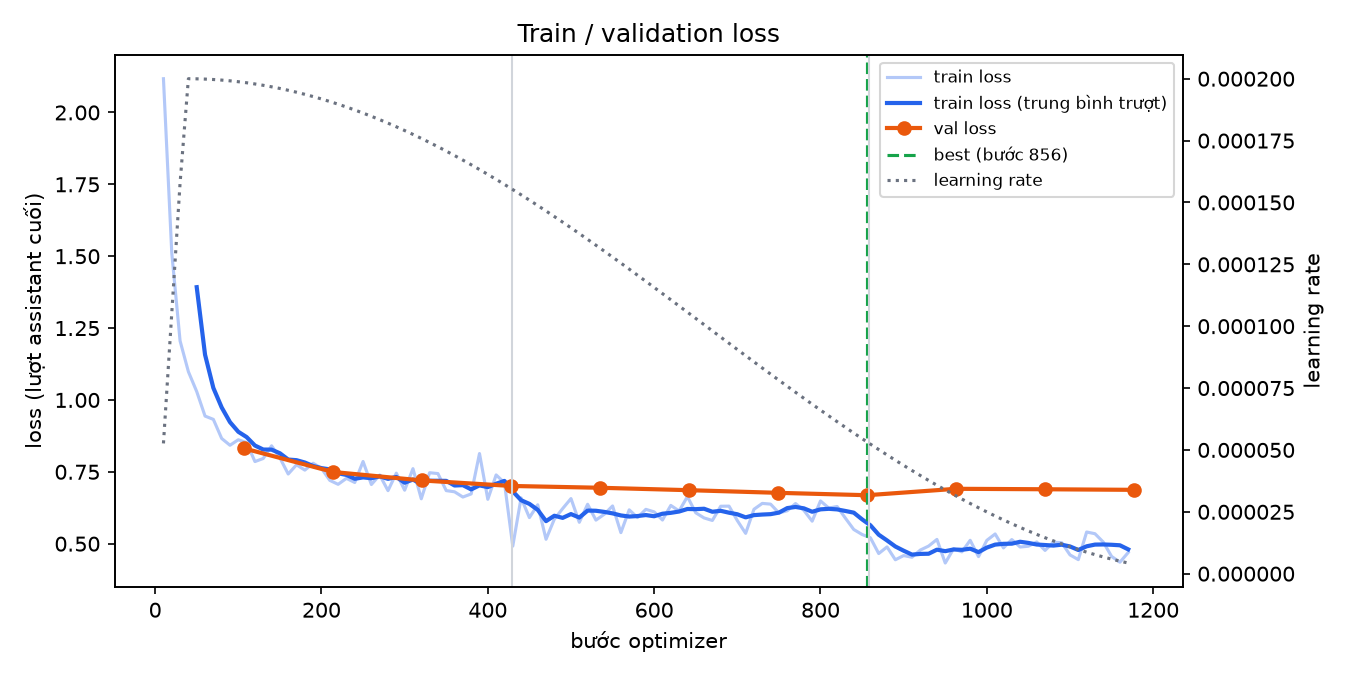

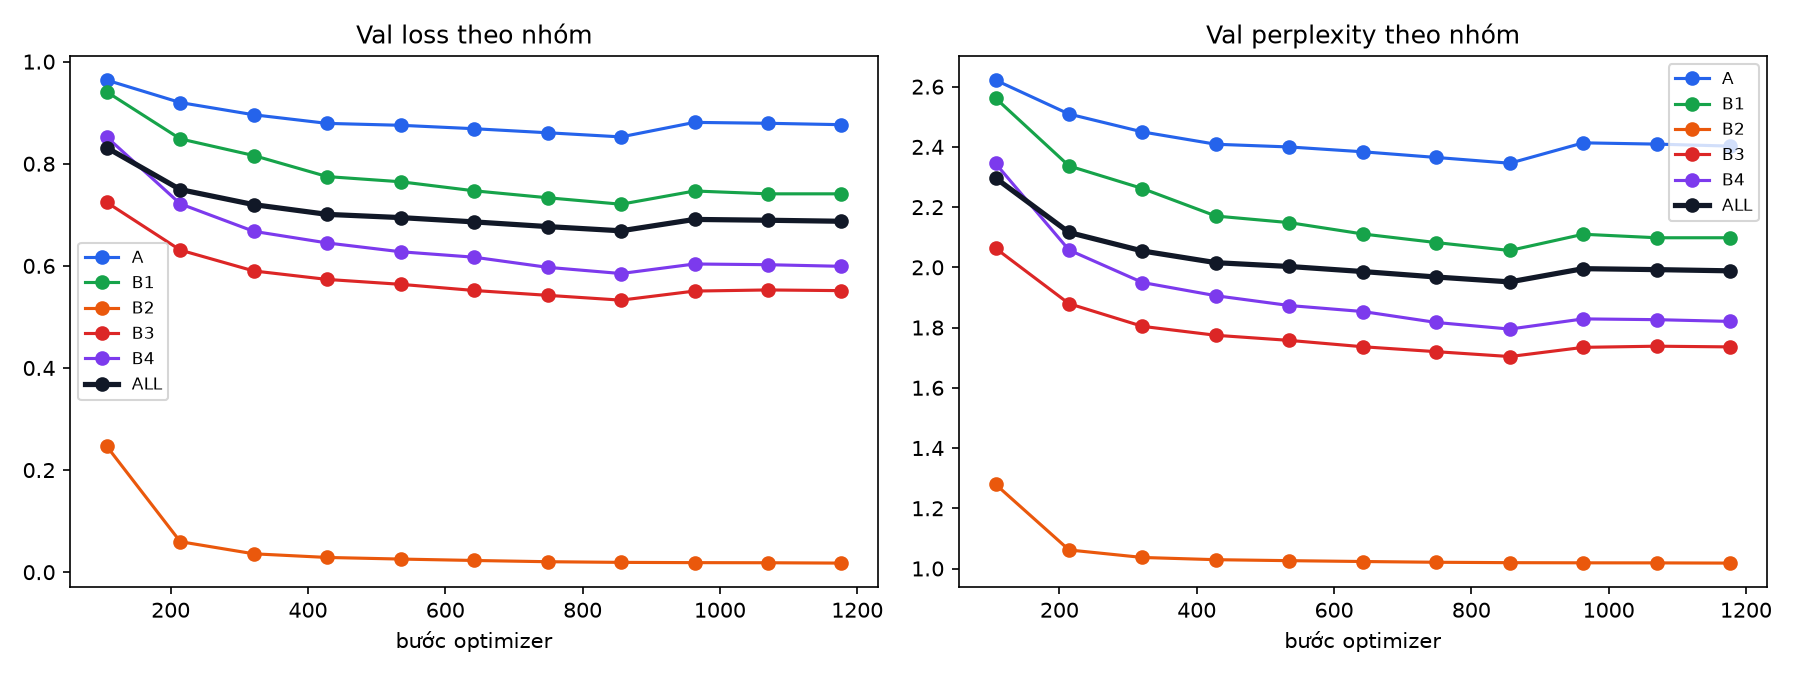

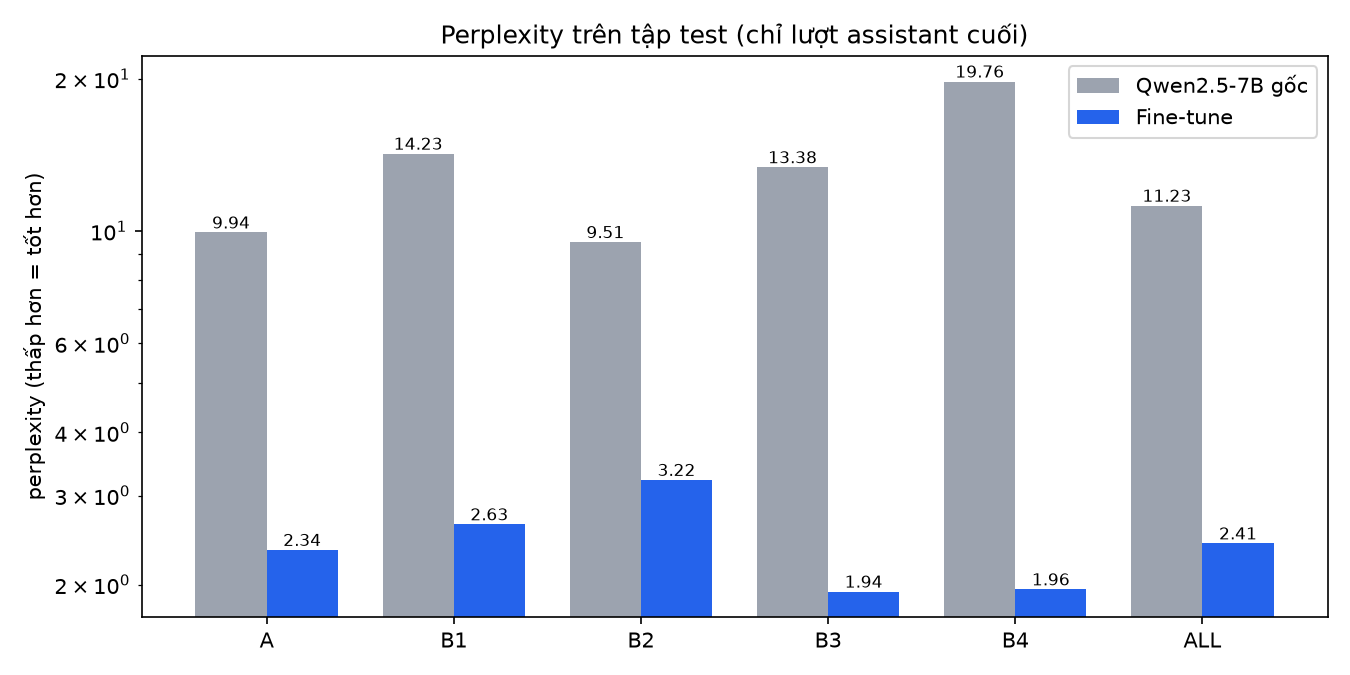

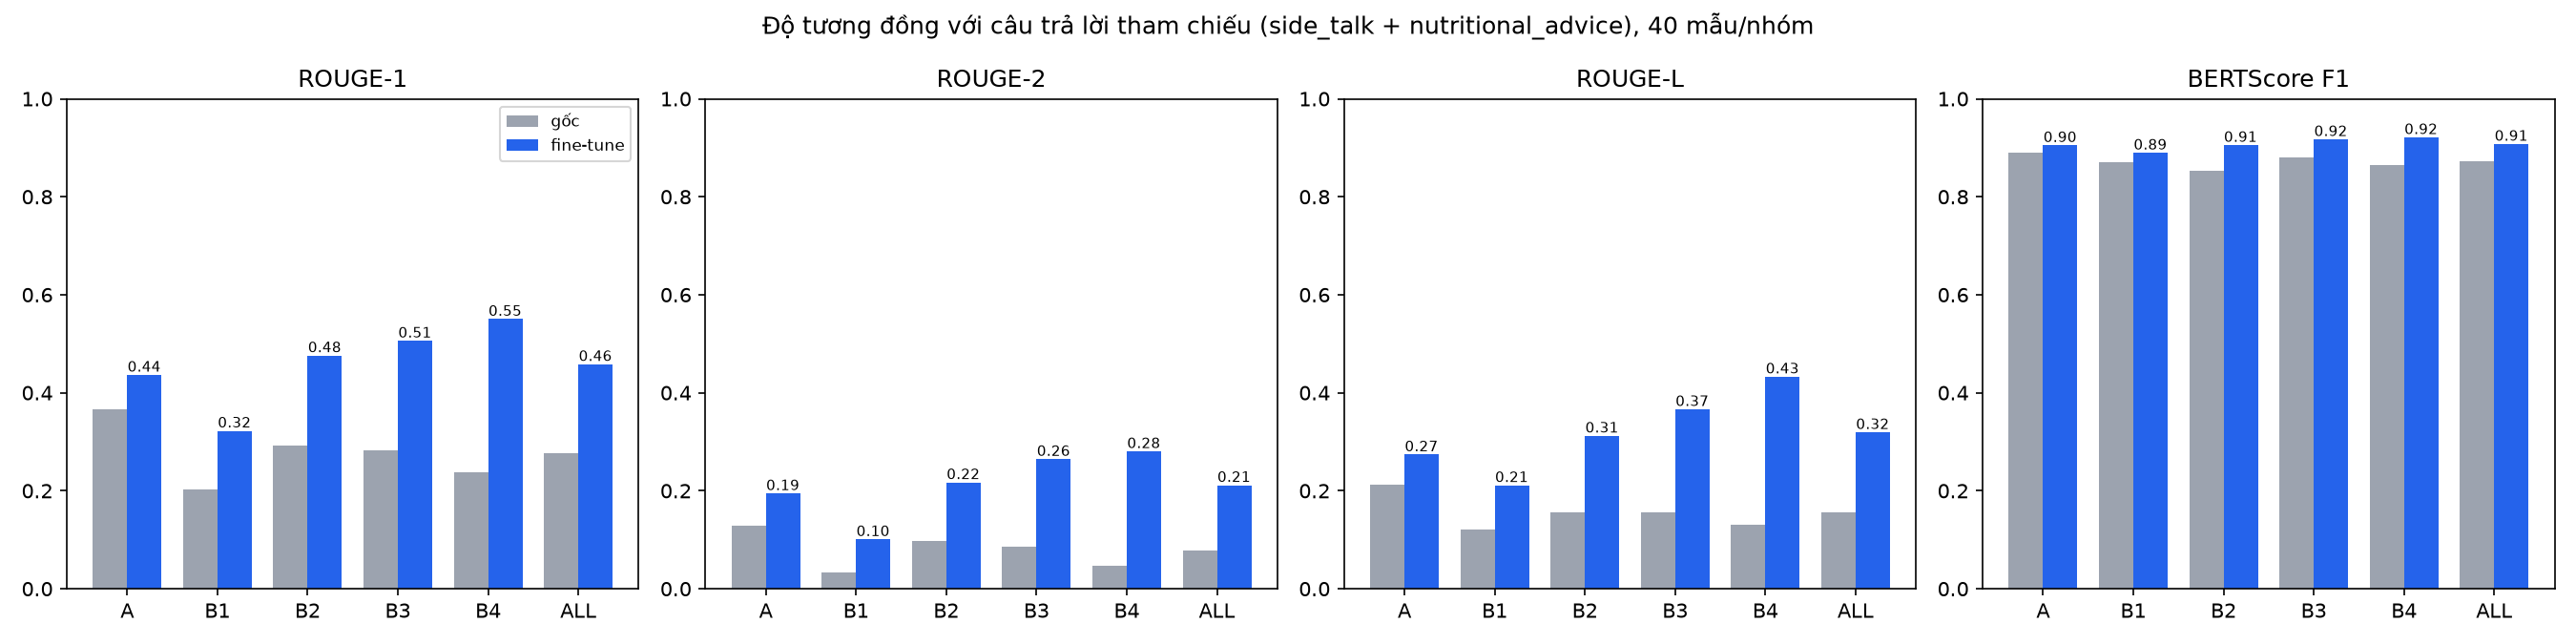

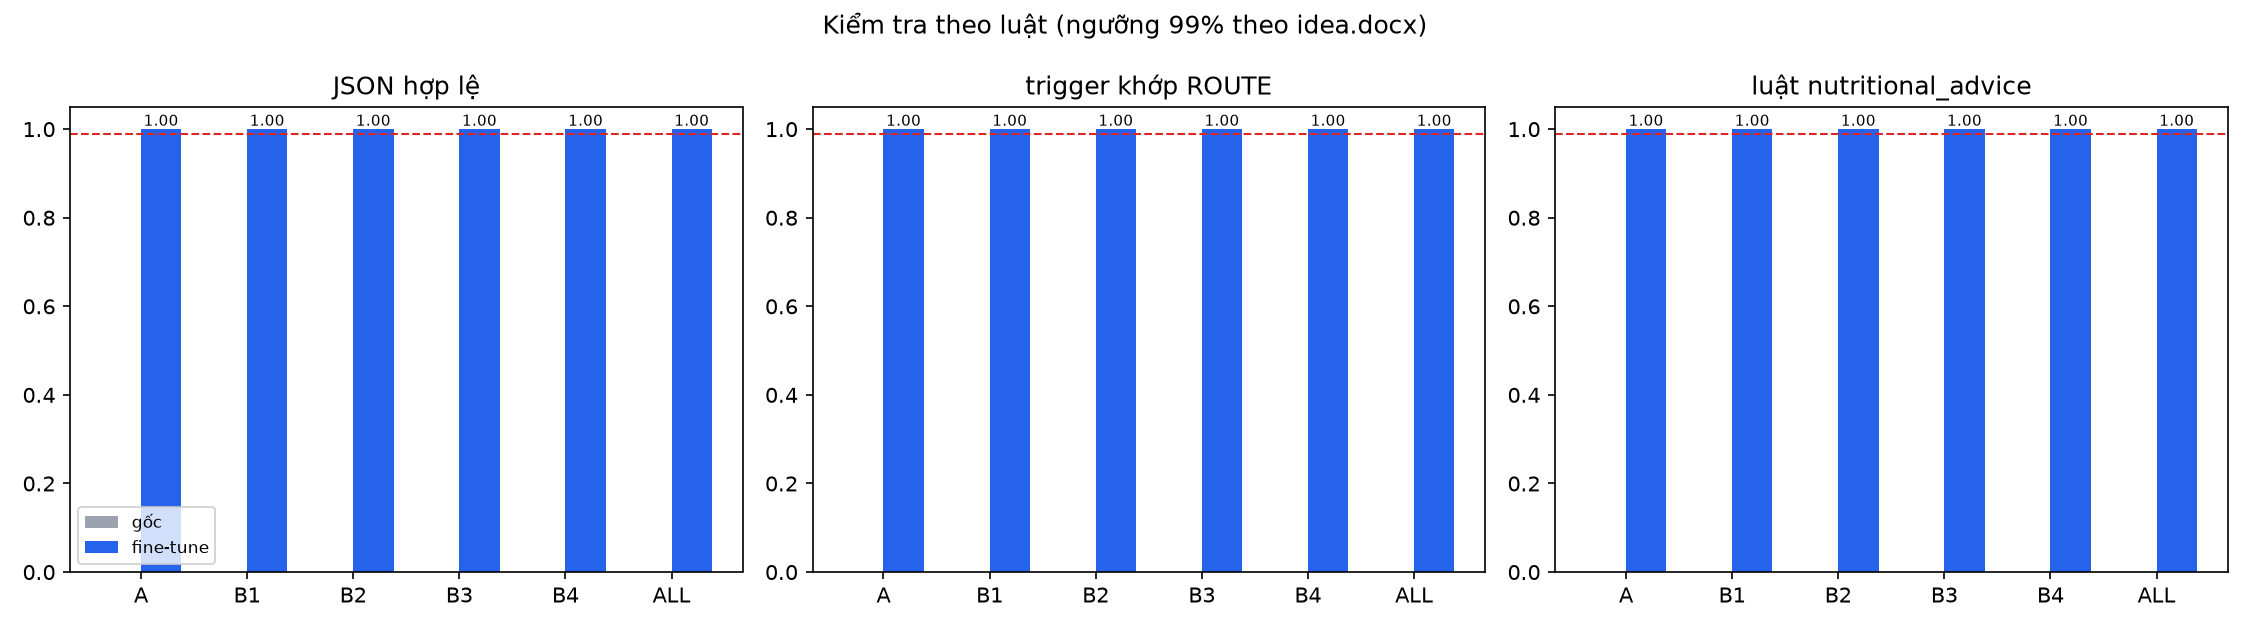

In [12]:
from IPython.display import Image, Markdown, display
display(Markdown(open(os.path.join(REPORT_DIR, "report.md"), encoding="utf-8").read().split("## Biểu đồ")[0]))
for p in figs:
    display(Image(filename=p))